In [26]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

# import phik
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, max_error
from sklearn.base import clone

# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

# Preprocessing

## Load Datasets 

-   Loading datasets and removing completely empty rows
-   Converting the Date column from text to real datetime values allowing chronological sorting, correct merging with the weather data on `Date`, extraction of date components (e.g. day of year for the sin/cos encoding) and proper date axes in plots. `dayfirst=True` ensures dates are read as dd/mm/yyyy, avoiding day and month being silently swapped for days 1–12.

In [27]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True) 
# Drop empty rows
df_freight = df_freight.dropna(how="all")

# Weather Data
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True) # dates are dd/mm/yyyy
# Drop empty rows
df_weather = df_weather.dropna(how="all")
df_weather.rename(columns={'date': 'Date'}, inplace=True)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_26940\1432804113.py:12: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.rename(columns={'date': 'Date'}, inplace=True)


## Clean and Align Data
### Merge two datasets (RhineFreightData.csv + WeatherDataBasel.csv)

-   Joining datasets matching rows by date

In [28]:
df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')

Verifying resulting dataser dataset shape 

In [29]:
print(f"Shape of df_freight: {df_freight.shape}")
print(f"Shape of df_weather: {df_weather.shape}")
print(f"Shape of df_complete: {df_complete.shape}")

Shape of df_freight: (1469, 8)
Shape of df_weather: (3652, 25)
Shape of df_complete: (1469, 32)


In [30]:
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avg_uv_index,avgtemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,1.0,2.0,...,0.0,1.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,1.0,4.0,...,0.0,1.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,1.0,...,0.0,1.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,1.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,1.0,-1.0,...,0.0,1.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


### Dropping columns that aren't essential
-   Dropping columns with no information or that duplicate other columns:
    -   **`avg_uv_index`, `uv_index`**: constant (value 1 on every day), so they have zero variance and cannot help any model.
    -   **`weather_code`**: one-to-one with `weather_descriptions` (17 codes -> 17 descriptions). Keeping both would duplicate the same information, and the numeric code would wrongly imply an order between weather types; the descriptions are one-hot encoded instead.
    -   **`wind_dir`**: text version of `wind_degree` (16 compass labels such as "WSW"), so it is redundant with the numeric column.

In [31]:
df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_26940\3426618150.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)


### Target Feature

-   Creating the target `Freight_5days`:
    -   rows without a freight price are removed, then the freight column is shifted 5 rows up so each day is paired with the price 5 business days later (our target). The last 5 rows have no future price and are dropped. This assumes the data is sorted by date with one row per business day.

In [32]:
df_complete.dropna(subset=['Freight'], inplace=True)
# Price 5 rows ahead (the last 5 rows get NaN because they have no future)
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)
# Drop those last 5 rows
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_26940\302708443.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_complete.dropna(subset=['Freight'], inplace=True)


### Feature encoding

-   Cyclical encoding of the day of year:
    -   the day number is mapped onto a circle (one full turn = one year) and represented by its sine and cosine. This keeps 31 December and 1 January close together instead of 364 days apart, and the (sin, cos) pair uniquely identifies each day. 
    -   It lets the model capture seasonal patterns, such as low Rhine water levels in late summer/autumn, which affect freight prices.

In [33]:
day = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * day / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * day / 365.25)

C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_26940\4121977553.py:1: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  day = df_complete['Date'].dt.dayofyear


C:\Users\Leonor Fandinga\AppData\Local\Temp\ipykernel_26940\1627195257.py:7: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  plt.xticks(month_starts.dayofyear, month_starts.strftime("%b"))


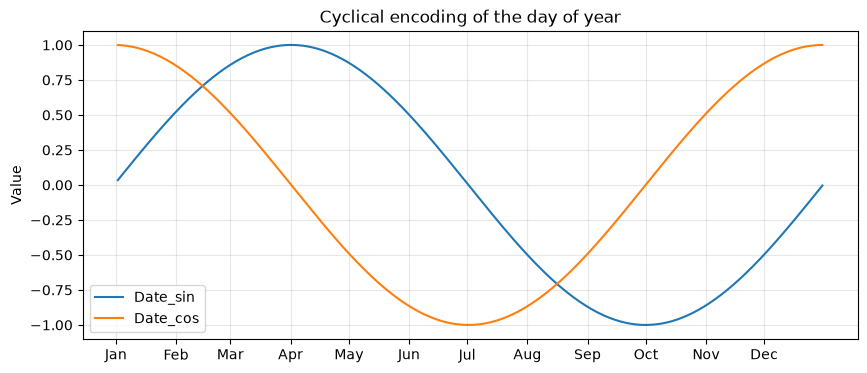

In [34]:
d = df_complete.assign(day=day).sort_values("day")
month_starts = pd.date_range("2021-01-01", periods=12, freq="MS")   # 1st of each month

plt.figure(figsize=(10, 4))
plt.plot(d["day"], d["Date_sin"], label="Date_sin")
plt.plot(d["day"], d["Date_cos"], label="Date_cos")
plt.xticks(month_starts.dayofyear, month_starts.strftime("%b"))
plt.ylabel("Value")
plt.title("Cyclical encoding of the day of year")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [35]:
# stripping the brackets and quotes from the weather_descriptions column
df_complete["weather_descriptions"] = df_complete["weather_descriptions"].str.strip("[]'")

-   One-hot encoding of `weather_descriptions` and `moon_phase`:
    -   Each category becomes a 0/1 column.
    -   `drop_first=True` removes one category per variable, because it is implied when all the other columns are 0 (e.g. if every `moon_*` column is 0, the day has the dropped moon phase). This avoids redundant columns, which matter for linear models like Ridge tree models are unaffected.

In [36]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions', 'moon_phase'],
                             prefix={'weather_descriptions': 'weather', 'moon_phase': 'moon'},
                             drop_first=True, dtype=int)

### Missing values
-   **`Kaub_level`** (13 values, gaps ≤ 2 days): forward-filled with the last known value. The river level changes slowly, so this is a close approximation, and unlike interpolation it only uses past information (no leakage).
-   **`freight_ar`**: dropped. About 50% of its values are missing, mostly in one continuous 726-day gap, so any imputation would invent a large part of the column.

In [37]:
# Kaub_level: fill each gap with the last known value (uses only past information)
df_complete["Kaub_level"] = df_complete["Kaub_level"].ffill()

# freight_ar: ~50% missing (one continuous gap of 726 days) -> drop the column
df_complete = df_complete.drop(columns=["freight_ar"])


# Modeling